# Ring-exchange model on the pyrochlore lattice

This notebook runs GFMC for the ring-exchange / Rokhsar-Kivelson Hamiltonian

$$H = -g \sum_{h} \bigl(|\circlearrowleft\rangle\langle\circlearrowright| + \text{h.c.}\bigr)
      + \mu \sum_{h} n^{\rm flip}_{h}\,, \qquad g = 1\,,$$

on the 128 hexagonal plaquettes of a periodic pyrochlore lattice with $N = 128$ sites
($2\times2\times2$ cubic cells), where $h$ runs over the hexagons and $n^{\rm flip}_{h}$ is 1 if hexagon $h$ is flippable.


* $\mu = 0$, pure ring exchange with $E_0 = -24.63446$.
* $\mu = 1$, the RK point with $E_0 = 0$.

In [1]:
import h5py
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from pygfmc import run
from pygfmc.hamiltonian import PlaquetteModel
from pygfmc.walkers import prepare_walkers_from_configs

print(f'JAX version : {jax.__version__}')
print(f'Backend     : {jax.default_backend()}')

rng = jax.random.PRNGKey(42)

JAX version : 0.9.2
Backend     : cpu


## Lattice, references and walkers

We load the lattice and a single valid ice configuration in the zero-flux sector.

In [2]:
DTYPE = jnp.float32

# lattice, one zero-flux ice configuration and the exact references, all in one file
with h5py.File('pyrochlore.h5', 'r') as f:
    hexagons   = f['hexagons'][:]          # (128, 6) site indices around each hexagon
    tetrahedra = f['tetrahedra'][:]        # (64, 4) site indices of each tetrahedron
    config     = f['ice_config'][:]        # one zero-flux ice configuration, (128,)
    print('sector of the configuration:', f.attrs['sector'])
    ref_mu0 = dict(f['reference/ring_exchange'].attrs)
    ref_rk  = dict(f['reference/rk_point'].attrs)

N, N_hex = config.shape[0], hexagons.shape[0]
print(f'N = {N} sites, {N_hex} hexagons, {len(tetrahedra)} tetrahedra')
assert np.all(config[tetrahedra].sum(axis=1) == 0), 'not an ice configuration'
print('ice rule (2 in, 2 out) holds on every tetrahedron')
print(f"mu = 0 (Lanczos)   : E0 = {ref_mu0['E0']:.5f},  <sum ring flips> = {ref_mu0['ring_flip_tot']:.4f}")
print(f"mu = 1 (RK point)  : E0 = {ref_rk['E0']:.1f},  flippable fraction = {ref_rk['flippable_frac']:.5f},"
      f"  <sum ring flips> = {ref_rk['ring_flip_tot']:.3f}")

N_WALKERS = 2048
walkers0  = prepare_walkers_from_configs(jnp.tile(jnp.asarray(config, dtype=DTYPE), (N_WALKERS, 1)))

sector of the configuration: zero_flux
N = 128 sites, 128 hexagons, 64 tetrahedra
ice rule (2 in, 2 out) holds on every tetrahedron
mu = 0 (Lanczos)   : E0 = -24.63446,  <sum ring flips> = 24.6345
mu = 1 (RK point)  : E0 = 0.0,  flippable fraction = 0.18334,  <sum ring flips> = 23.468


## Observables

We compute the flippable fraction $\frac{1}{N_{h}} \sum_{h} \langle n^{\rm flip}_{h} \rangle$, with $N_h = 128$ hexagons, which is diagonal.

In [3]:
flippable = PlaquetteModel.create(hexagons, g=0.0, mu=1.0 / N_hex, dtype=DTYPE)

## Sweep of the RK potential $\mu$

For each $\mu$ we run GFMC from this initial configuration with the discrete `multi_step` propagation of
$\lambda - H$. Its diagonal element $\lambda - \mu\, n^{\rm flip}$ must stay positive. We use $\lambda = 40$ for the whole sweep.
Each branching step holds `step_size = 4` sub-steps, and we use the projection windows `p = 8, 16, 32, 64`.

In [4]:
MU_VALUES = [0.0, 0.25, 0.5, 0.75, 1.0]

results = {}
for mu in MU_VALUES:
    rng, k_run = jax.random.split(rng)
    h = PlaquetteModel.create(hexagons, g=1.0, mu=mu, dtype=DTYPE)
    _, energy, obs, stats, _ = run(
        walkers0, 2000, h, lam=40., step_size=4, guide=None, p_array=[8, 16, 32, 64],
        rng_key=k_run, method='multi_step', warmup_steps=300, verbosity=0,
        diag_operators={'flippable': flippable},
    )
    results[mu] = (energy, obs)
    p = max(energy)                              # deepest window
    print(f'mu = {mu:4.2f}:  E = {energy[p]:+9.4f}   flippable = {float(obs["flippable"][p]):.4f}   '
          f'n_eff(p={p}) = {stats["effective_sample_size"][-1]:.0f}')

mu = 0.00:  E =  -24.6317   flippable = 0.2010   n_eff(p=64) = 264


mu = 0.25:  E =  -18.2691   flippable = 0.1967   n_eff(p=64) = 359


mu = 0.50:  E =  -12.0388   flippable = 0.1925   n_eff(p=64) = 495


mu = 0.75:  E =   -5.9465   flippable = 0.1882   n_eff(p=64) = 868


mu = 1.00:  E =   +0.0000   flippable = 0.1833   n_eff(p=64) = 2048


## Results

The plot shows the energy and flippable fraction across the sweep for each
window $p$, with the exact energies at both endpoints and the exact flippable fraction at the RK point (black stars).

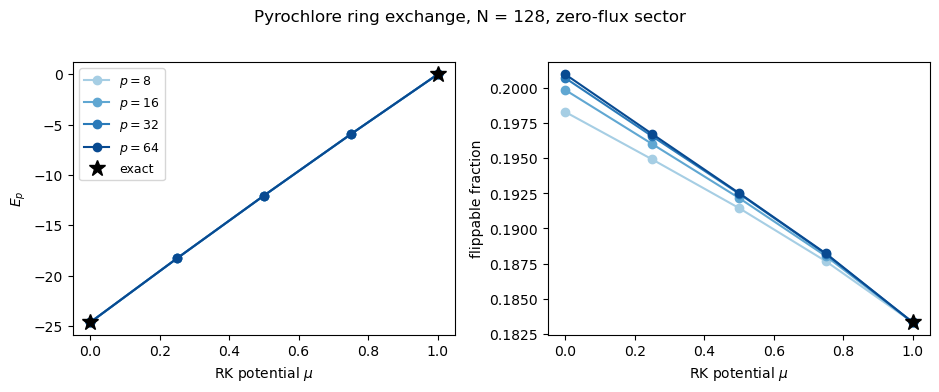

In [5]:
p_windows = sorted(results[MU_VALUES[0]][0])     # the windows p of the runs
colors = plt.cm.Blues(np.linspace(0.35, 0.9, len(p_windows)))
mu_arr = np.array(MU_VALUES)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
for p, color in zip(p_windows, colors):
    axes[0].plot(mu_arr, [results[mu][0][p] for mu in MU_VALUES], 'o-', color=color, label=f'$p={p}$')
    axes[1].plot(mu_arr, [float(results[mu][1]['flippable'][p]) for mu in MU_VALUES], 'o-', color=color)

axes[0].plot([0, 1], [ref_mu0['E0'], ref_rk['E0']], 'k*', ms=12, label='exact')
axes[1].plot([1], [ref_rk['flippable_frac']], 'k*', ms=12)

for ax, ylabel in zip(axes, [r'$E_p$', 'flippable fraction']):
    ax.set_xlabel(r'RK potential $\mu$')
    ax.set_ylabel(ylabel)
axes[0].legend(fontsize=9)
plt.suptitle(f'Pyrochlore ring exchange, N = {N}, zero-flux sector', y=1.02)
plt.tight_layout()
plt.show()

## Exact results at the RK point

The energy is exact at the RK point. See discussion in the toric code notebook.